# 01 - Geometry, from 2D grids to 3D cells

A representation says where an interpretation is, in its own terms: a 2D grid is an origin,
two steps and elevations; a well trajectory a curve; an IJK grid pillars and cells.
`geometry_of` evaluates any of them into the same answer - points and a topology - placed in
a coordinate system you choose. It runs on **Lutetia**, a synthetic model (CC BY 4.0) built on boreholes of the BRGM Banque du sous-sol (Licence Ouverte 2.0), modified for the example: [geosiris-technologies/energyml-lutetia](https://github.com/geosiris-technologies/energyml-lutetia). The first run downloads it (27 MB) at the commit this repository pins; see `_lutetia.py`.

```
pip install energyml-rust matplotlib pandas
```

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from energyml.rust.epc import Epc
from energyml.rust.resqml import geometry_of

from _lutetia import lutetia

root = lutetia()
pkg = Epc.open(str(root / "package" / "Lutetia.epc"))

## One call for every kind of representation

Each answer has a `kind`, the CRS's EPSG code and `patches`; a patch has `points` (x, y, z
flattened) and a `topology`: `points`, `polylines`, `grid`, `triangles` or `hexahedra`. A
representation this build cannot evaluate is **refused by name**, never drawn empty.

In [2]:
KINDS = ["PointSetRepresentation", "PolylineSetRepresentation", "Grid2dRepresentation",
         "TriangulatedSetRepresentation", "WellboreTrajectoryRepresentation",
         "WellboreFrameRepresentation", "IjkGridRepresentation", "SubRepresentation",
         "BlockedWellboreRepresentation", "NonSealedSurfaceFrameworkRepresentation"]
rows = []
for kind in KINDS:
    one = pkg.find(kind)[0]
    try:
        shape = geometry_of(pkg, one.uri)
        rows.append({"type": kind, "example": one.title, "EPSG": shape["epsg"],
                     "topology": ", ".join(sorted({p["topology"] for p in shape["patches"]})),
                     "points": sum(len(p["points"]) // 3 for p in shape["patches"]), "refused": ""})
    except Exception as refusal:
        rows.append({"type": kind, "example": one.title, "refused": str(refusal)})
pd.DataFrame(rows).astype({"EPSG": "Int64", "points": "Int64"}).astype(object).fillna("")

,type,example,EPSG,topology,points,refused
0,PointSetRepresentation,Lower Lutetian - base,2154,points,1,
1,PolylineSetRepresentation,"H6 - top of the Chalk, faulted - lips",2154,polylines,158,
2,Grid2dRepresentation,"H6 - top of the Chalk, in time",2154,grid,6715,
3,TriangulatedSetRepresentation,H3 - top of the Ypresian (triangulated),2154,triangles,6715,
4,WellboreTrajectoryRepresentation,BSS000NVHN - trajectory,2154,polylines,13,
5,WellboreFrameRepresentation,BSS003CIKW - frame,2154,polylines,6,
6,IjkGridRepresentation,"Ypresian-Chalk grid, faulted",2154,hexahedra,81228,
7,SubRepresentation,Productive reservoir - Chalk,2154,hexahedra,53720,
8,BlockedWellboreRepresentation,GTH-2 - blocked,,,,`BlockedWellboreRepresentation` is not evaluat...
9,NonSealedSurfaceFrameworkRepresentation,"Lutetia - scenario B, non-sealed framework",,,,`NonSealedSurfaceFrameworkRepresentation` is n...


## Placement

The same object in three coordinate systems:

- `local`: the representation's own axes, as the file writes them;
- `projected` (the default): the local CRS's offset, rotation and vertical direction
  applied, so that the object sits on the map of its projected CRS;
- `metres`: projected, with the units taken to metres, and refused when the CRS states a unit
  this build cannot convert.

Lutetia's local CRSs have no offset and no rotation, so the three agree here. A package whose
local grid is rotated would not: only `projected` would put it on a map.

In [3]:
well = pkg.find("WellboreTrajectoryRepresentation")[0]
pd.DataFrame(
    {placement: geometry_of(pkg, well.uri, placement)["patches"][0]["points"][:3]
     for placement in ("local", "projected", "metres")},
    index=["x", "y", "z"],
).T

,x,y,z
local,651050.797949,6.861791e+06,32.5
projected,651050.797949,6.861791e+06,32.5
metres,651050.797949,6.861791e+06,32.5


## The horizons and the wells, in 3D

The 2D grids come back with their axis counts, `fastest` and `slowest`, so the points reshape
straight into a surface.

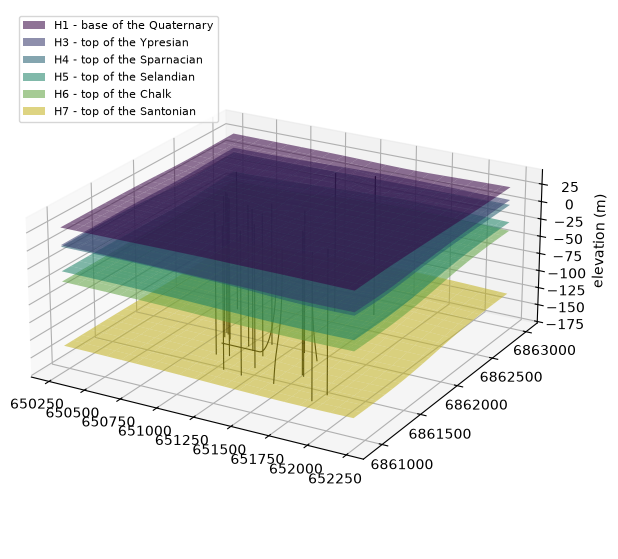

In [4]:
HORIZONS = ["H1 - base of the Quaternary", "H3 - top of the Ypresian", "H4 - top of the Sparnacian",
            "H5 - top of the Selandian", "H6 - top of the Chalk", "H7 - top of the Santonian"]

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(projection="3d")
for title, colour in zip(HORIZONS, plt.cm.viridis(np.linspace(0, 1, len(HORIZONS)))):
    grid = pkg.find("Grid2dRepresentation", title)[0]
    patch = geometry_of(pkg, grid.uri)["patches"][0]
    xyz = patch["points"].reshape(patch["slowest"], patch["fastest"], 3)
    ax.plot_surface(xyz[..., 0], xyz[..., 1], xyz[..., 2], color=colour, alpha=0.55,
                    rstride=4, cstride=4, linewidth=0, label=title)
for well in pkg.find("WellboreTrajectoryRepresentation"):
    for patch in geometry_of(pkg, well.uri)["patches"]:
        xyz = patch["points"].reshape(-1, 3)
        ax.plot(xyz[:, 0], xyz[:, 1], xyz[:, 2], "k-", lw=0.8)
ax.set_box_aspect((1, 1, 0.45))
ax.set_zlabel("elevation (m)")
ax.ticklabel_format(useOffset=False, style="plain")
ax.legend(loc="upper left", fontsize=8)
ax.view_init(elev=22, azim=-60)
plt.show()

## An IJK grid: hexahedra

An IJK grid comes back as `hexahedra`: `cells` holds 8 node indices per cell, and `cell_index` the
RESQML number of each cell (I fastest, then J, then K) - **empty when the two coincide**, that
is when every cell is there, in order. A cell the file marks undefined is not in the answer,
which is why the numbers are needed: on this faulted grid, the cells after a gap no longer sit
at their own number. The cell centres along one row of J make a vertical
section, where the faults show as steps.

78 x 84 x 10 = 65520 cells in the grid, 65401 in the answer


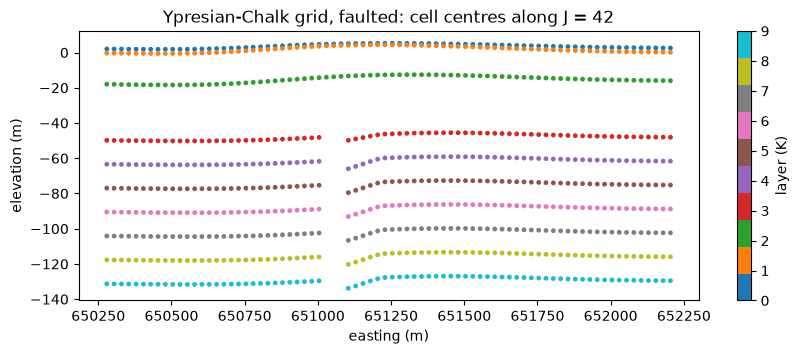

In [5]:
grid = pkg.find("IjkGridRepresentation", "Ypresian-Chalk grid, faulted")[0]
patch = geometry_of(pkg, grid.uri)["patches"][0]
ni, nj, nk = patch["dimensions"]
nodes = patch["points"].reshape(-1, 3)
corners = patch["cells"].reshape(-1, 8)
centres = nodes[corners].mean(axis=1)
number = patch["cell_index"] if len(patch["cell_index"]) else np.arange(len(corners))
i, j, k = number % ni, number // ni % nj, number // (ni * nj)
print(f"{ni} x {nj} x {nk} = {ni * nj * nk} cells in the grid, {len(corners)} in the answer")

row = j == nj // 2
fig, ax = plt.subplots(figsize=(10, 3.5))
shown = ax.scatter(centres[row, 0], centres[row, 2], c=k[row], s=6, cmap="tab10")
fig.colorbar(shown, ax=ax, label="layer (K)")
ax.set_title(f"{grid.title}: cell centres along J = {nj // 2}")
ax.set_xlabel("easting (m)")
ax.set_ylabel("elevation (m)")
ax.ticklabel_format(useOffset=False, style="plain")
plt.show()

## The other notebooks

- [00 - What is in this package?](00-what-is-in-a-package.ipynb)
- [02 - Arrays and properties](02-arrays-and-properties.ipynb)
- [03 - Is this package valid?](03-is-this-package-valid.ipynb)
- [04 - A package from nothing](04-a-package-from-nothing.ipynb)
- [05 - Editing a package](05-editing-a-package.ipynb)
- [06 - Exporting to other tools](06-exporting.ipynb)